# Prediksi Customer Churn

Dataset: Telco Customer Churn

## Latar belakang
Perusahaan layanan berlangganan perlu mengetahui pelanggan yang berpotensi berhenti berlangganan. Pada studi kasus ini, data pelanggan dianalisis untuk melihat pola churn dan mencoba membuat model prediksi sederhana.

## Tujuan
Analisis dilakukan untuk memahami data pelanggan, melihat pola churn, membandingkan dua model klasifikasi, dan menafsirkan hasilnya sebagai bahan pertimbangan bisnis.


## 1. Instalasi dan import library


In [ ]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## 2. Memuat dataset publik

Dataset Telco Customer Churn memuat informasi pelanggan layanan telekomunikasi dan kolom `Churn` sebagai label apakah pelanggan berhenti berlangganan. CSV dimuat langsung dari repositori publik agar tidak perlu mengunggah file secara manual.

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/IBM/ telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv".replace(" ", "")

try:
    df = pd.read_csv(DATA_URL)
except Exception as e:
    raise RuntimeError(
        "Dataset gagal diunduh. Periksa koneksi internet Colab atau unduh CSV "
        "dari repositori publik IBM Telco Customer Churn lalu unggah ke Colab."
    ) from e

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Memeriksa kualitas data

Periksa tipe data, nilai kosong, data duplikat, dan jumlah pelanggan pada masing-masing kelas.

In [ ]:
print("Informasi dataset:")
df.info()

print("\nJumlah nilai kosong per kolom:")
display(df.isna().sum().sort_values(ascending=False).head(15))

print("\nJumlah baris duplikat:", df.duplicated().sum())
print("\nDistribusi target:")
display(df["Churn"].value_counts(dropna=False).rename("jumlah"))
display((df["Churn"].value_counts(normalize=True, dropna=False) * 100).round(2).rename("persentase"))

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Jumlah baris duplikat: 0

Distribusi target:


,jumlah
Churn,
No,5174
Yes,1869


,persentase
Churn,
No,73.46
Yes,26.54


In [ ]:
# TotalCharges kadang tersimpan sebagai teks/spasi kosong, sehingga dikonversi ke numerik.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Nilai kosong setelah konversi TotalCharges:", df["TotalCharges"].isna().sum())
display(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].describe(include="all"))

Nilai kosong setelah konversi TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.000000,7043.000000,7032.000000,7043
unique,NaN,NaN,NaN,2
top,NaN,NaN,NaN,No
freq,NaN,NaN,NaN,5174
mean,32.371149,64.761692,2283.300441,NaN
std,24.559481,30.090047,2266.771362,NaN
min,0.000000,18.250000,18.800000,NaN
25%,9.000000,35.500000,401.450000,NaN
50%,29.000000,70.350000,1397.475000,NaN
75%,55.000000,89.850000,3794.737500,NaN


## 4. Eksplorasi data dan visualisasi

Grafik digunakan untuk melihat jumlah pelanggan yang churn serta perbedaan lama berlangganan dan biaya bulanan pada tiap kelompok.

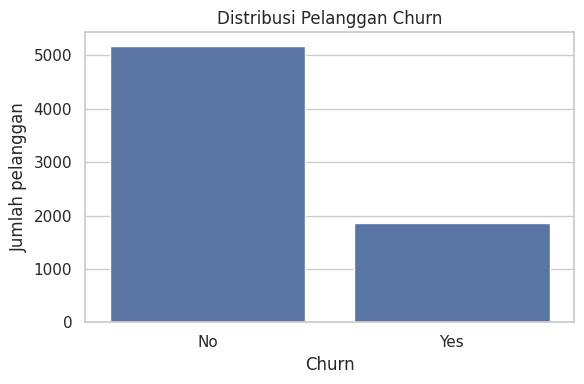

Persentase churn pada dataset: 26.54%


In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Distribusi Pelanggan Churn")
plt.xlabel("Churn")
plt.ylabel("Jumlah pelanggan")
plt.tight_layout()
plt.show()

churn_rate = (df["Churn"].value_counts(normalize=True).get("Yes", 0) * 100)
print(f"Persentase churn pada dataset: {churn_rate:.2f}%")

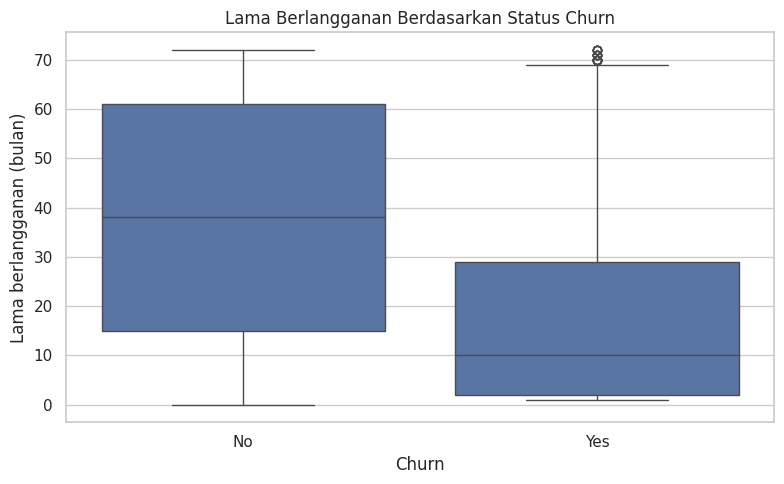

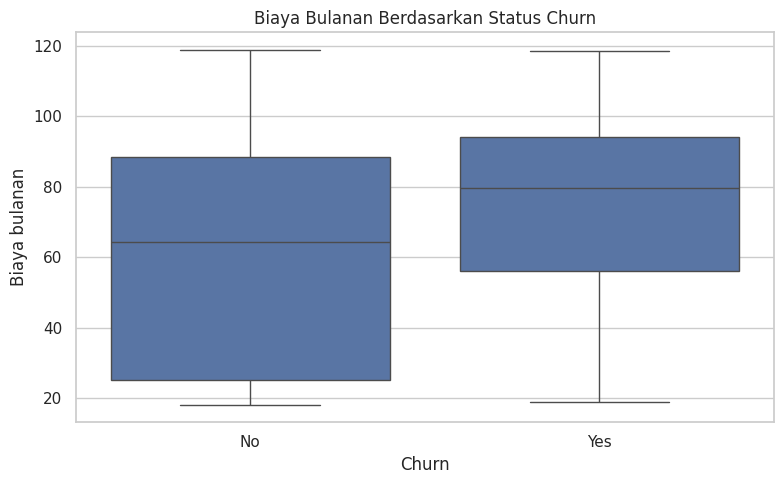

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Lama Berlangganan Berdasarkan Status Churn")
plt.xlabel("Churn")
plt.ylabel("Lama berlangganan (bulan)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Biaya Bulanan Berdasarkan Status Churn")
plt.xlabel("Churn")
plt.ylabel("Biaya bulanan")
plt.tight_layout()
plt.show()

In [ ]:
# Ringkasan numerik per status churn
summary = df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median().round(2)
display(summary)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1683.60
Yes,10.0,79.65,703.55


## 5. Menentukan fitur dan target

Kolom `customerID` tidak digunakan karena hanya berfungsi sebagai identitas pelanggan. Nilai `Churn` diubah menjadi 0 (`No`) dan 1 (`Yes`). Proses preprocessing dimasukkan ke dalam pipeline agar parameternya dipelajari dari data latih saja.

In [ ]:
data = df.copy()
data = data.drop(columns=["customerID"], errors="ignore")
data["Churn"] = data["Churn"].map({"No": 0, "Yes": 1})
data = data.dropna(subset=["Churn"])

X = data.drop(columns=["Churn"])
y = data["Churn"].astype(int)

# Kolom kategorikal dan numerik
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()

print("Jumlah fitur:", X.shape[1])
print("Fitur kategorikal:", categorical_cols)
print("Fitur numerik:", numeric_cols)
print("\nProporsi target:")
display(y.value_counts(normalize=True).rename("proporsi").round(3))

Jumlah fitur: 19
Fitur kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Fitur numerik: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Proporsi target:


,proporsi
Churn,
0,0.735
1,0.265


## 6. Membagi data train, validation, dan test

Data dibagi menjadi 60% train, 20% validation, dan 20% test dengan `stratify` agar proporsi kelas relatif terjaga. Validation digunakan untuk memilih model, sedangkan test hanya digunakan untuk evaluasi akhir agar penilaian akhir tidak ikut memengaruhi pemilihan model.

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Train: (4225, 19) Validation: (1409, 19) Test: (1409, 19)


## 7. Membuat pipeline preprocessing dan model

Nilai numerik yang kosong diisi dengan median, sedangkan nilai kategorikal diisi dengan modus. Kolom kategorikal diubah menggunakan One-Hot Encoding. Model yang dibandingkan adalah Logistic Regression dan Random Forest.

In [ ]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_cols),
    ("categorical", categorical_preprocessor, categorical_cols)
])

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced",
                                     random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

## 8. Melatih dan membandingkan model

Accuracy ditampilkan bersama precision, recall, F1-score, dan ROC-AUC. Metrik tersebut membantu melihat kinerja model dari beberapa sisi, terutama kemampuan menemukan pelanggan yang churn.

In [ ]:
def get_metrics(model, X_eval, y_eval):
    pred = model.predict(X_eval)
    prob = model.predict_proba(X_eval)[:, 1]
    return {
        "accuracy": accuracy_score(y_eval, pred),
        "precision_churn": precision_score(y_eval, pred, zero_division=0),
        "recall_churn": recall_score(y_eval, pred, zero_division=0),
        "f1_churn": f1_score(y_eval, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, prob)
    }

validation_results = []
for name, model in models.items():
    print("Melatih:", name)
    model.fit(X_train, y_train)
    row = {"model": name, **get_metrics(model, X_val, y_val)}
    validation_results.append(row)

validation_df = pd.DataFrame(validation_results).sort_values("f1_churn", ascending=False)
display(validation_df.round(3))

Melatih: Logistic Regression
Melatih: Random Forest


,model,accuracy,precision_churn,recall_churn,f1_churn,roc_auc
0,Logistic Regression,0.749,0.517,0.821,0.634,0.859
1,Random Forest,0.800,0.621,0.631,0.626,0.848


## 9. Memilih model dan melakukan evaluasi akhir

Model dengan F1-score churn tertinggi pada validation set dipilih untuk evaluasi akhir menggunakan test set.

In [ ]:
best_model_name = validation_df.iloc[0]["model"]
best_model = models[best_model_name]

print("Model terpilih berdasarkan F1 validation:", best_model_name)
test_metrics = get_metrics(best_model, X_test, y_test)
display(pd.DataFrame([test_metrics], index=[best_model_name]).round(3))

y_test_pred = best_model.predict(X_test)
y_test_prob = best_model.predict_proba(X_test)[:, 1]

print("\nClassification report:")
print(classification_report(
    y_test, y_test_pred, target_names=["Tidak churn", "Churn"], zero_division=0
))

Model terpilih berdasarkan F1 validation: Logistic Regression


,accuracy,precision_churn,recall_churn,f1_churn,roc_auc
Logistic Regression,0.742,0.508,0.81,0.625,0.832



Classification report:
              precision    recall  f1-score   support

 Tidak churn       0.91      0.72      0.80      1035
       Churn       0.51      0.81      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.81      0.74      0.76      1409



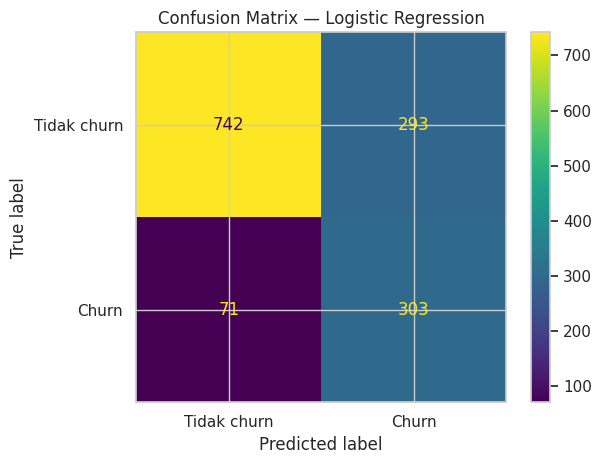

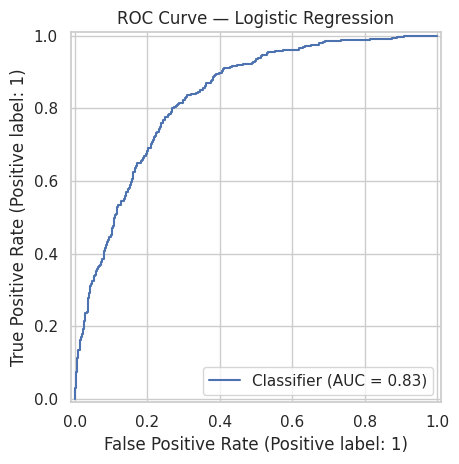

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=["Tidak churn", "Churn"],
    values_format="d"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_test_prob)
plt.title(f"ROC Curve — {best_model_name}")
plt.tight_layout()
plt.show()

## 10. Contoh prediksi dan interpretasi

Bagian ini menampilkan satu contoh prediksi dari data test. Probabilitas model merupakan perkiraan, bukan kepastian bahwa pelanggan akan berhenti berlangganan.

In [ ]:
sample = X_test.iloc[[0]]
actual = int(y_test.iloc[0])
predicted = int(best_model.predict(sample)[0])
prob_churn = float(best_model.predict_proba(sample)[0, 1])

print("Label aktual:", "Churn" if actual == 1 else "Tidak churn")
print("Prediksi model:", "Churn" if predicted == 1 else "Tidak churn")
print(f"Probabilitas churn dari model: {prob_churn:.1%}")
display(sample)

Label aktual: Tidak churn
Prediksi model: Tidak churn
Probabilitas churn dari model: 23.9%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
2881,Female,0,Yes,No,31,Yes,No,DSL,Yes,No,No,Yes,No,Yes,One year,Yes,Electronic check,64.0,1910.75


## 11. Menyimpan hasil proyek

Model terpilih dan tabel metrik disimpan agar hasil analisis dapat diperiksa kembali.

In [ ]:
from pathlib import Path
import joblib
import json

output_dir = Path("/content/hasil_project")
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(best_model, output_dir / "best_churn_model.joblib")
validation_df.to_csv(output_dir / "validation_metrics.csv", index=False)
pd.DataFrame([{"model": best_model_name, **test_metrics}]).to_csv(
    output_dir / "test_metrics.csv", index=False
)

with open(output_dir / "project_summary.json", "w", encoding="utf-8") as f:
    json.dump({
        "project": "Customer Churn Prediction",
        "selected_model": best_model_name,
        "test_metrics": test_metrics,
        "random_state": RANDOM_STATE
    }, f, indent=2)

print("Artefak tersimpan di:", output_dir)
print(sorted(p.name for p in output_dir.iterdir()))

Artefak tersimpan di: /content/hasil_project
['best_churn_model.joblib', 'project_summary.json', 'test_metrics.csv', 'validation_metrics.csv']


## 12. Mengunduh notebook dan hasil dari Google Colab


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive("/content/hasil_project", "zip", "/content/hasil_project")
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>